
# KoELECTRA Merchant Category Training

이 노트북은 업로드된 merchant category dataset을 사용해 다음을 수행합니다.

- `merchant_text` + `normalized_merchant_text` 기반 입력 생성
- `GroupKFold` 기반 교차검증 (`merchant_family_id` 그룹 누수 방지)
- `transformers.Trainer`로 KoELECTRA fine-tuning
- 최종 모델 학습 및 저장
- 테스트셋 성능 평가
- 테스트셋 혼동행렬 시각화 및 저장

기본 전제:
- `train.csv`, `valid.csv`, `test.csv`는 이미 생성되어 있음
- 최종 테스트셋은 교차검증에 사용하지 않음
- 교차검증은 `train + valid` 풀에서 수행


In [24]:
!nvidia-smi

Tue Mar 10 17:09:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.211.01             Driver Version: 570.211.01     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla V100S-PCIE-32GB          On  |   00000000:10:00.0 Off |                    0 |
| N/A   31C    P0             25W /  250W |       0MiB /  32768MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [25]:
# 필요 시 최초 1회 실행
!pip install -U transformers datasets accelerate scikit-learn pandas matplotlib openpyxl

Defaulting to user installation because normal site-packages is not writeable


In [26]:
import os
os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"]="3"

In [27]:
import os
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

import matplotlib.pyplot as plt

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed,
)

print('torch:', torch.__version__)
print('cuda available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('gpu:', torch.cuda.get_device_name(0))


torch: 2.10.0+cu128
cuda available: True
gpu: Tesla V100S-PCIE-32GB


In [28]:
from pathlib import Path

# path/config
BASE_DIR = Path("./data/merchant_category_dataset_v1")
TRAIN_PATH = BASE_DIR / 'train.csv'
VALID_PATH = BASE_DIR / 'valid.csv'
TEST_PATH = BASE_DIR / 'test.csv'

MODEL_CANDIDATES = {
    'stable_default': 'klue/roberta-base',
    'electra_alternative': 'beomi/KcELECTRA-base-v2022',
    'legacy_reference': 'monologg/koelectra-base-v3-discriminator',
}
SELECTED_MODEL_NAME = MODEL_CANDIDATES['stable_default']
MODEL_NAME = SELECTED_MODEL_NAME
OUTPUT_ROOT = BASE_DIR / 'training_outputs'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

SEED = 42
NUM_FOLDS = 5
MAX_LENGTH = 64
NUM_EPOCHS = 6
LEARNING_RATE = 3e-5
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
WEIGHT_DECAY = 0.05
WARMUP_STEP_RATIO = 0.1
EARLY_STOPPING_PATIENCE = 2
GRADIENT_ACCUMULATION_STEPS = 2
MAX_GRAD_NORM = 1.0
USE_FP16 = torch.cuda.is_available()
SERVICE_FALLBACK_LABEL = '기타서비스'
SERVICE_FALLBACK_THRESHOLDS = (0.35, 0.40, 0.45, 0.50)
TARGET_LABELS = (
    '카페',
    '미용',
    '쇼핑/패션',
    '식비',
    '편의점',
)

print('selected model checkpoint:', SELECTED_MODEL_NAME)

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DEVICE


selected model checkpoint: klue/roberta-base


'cuda'

In [29]:

# 데이터 로드
train_df = pd.read_csv(TRAIN_PATH)
valid_df = pd.read_csv(VALID_PATH)
test_df = pd.read_csv(TEST_PATH)

print('train:', train_df.shape)
print('valid:', valid_df.shape)
print('test :', test_df.shape)

train_df.head(3)


train: (31555, 11)
valid: (4500, 11)
test : (4500, 11)


,sample_id,split,category_id,category_name,merchant_family_id,merchant_family,merchant_text,normalized_merchant_text,family_type,family_source,variant_source
0,S000284,train,0,교육비,F0001,메가스터디 강남캠퍼스,MEGASTUDY,megastudy,online_edu,curated_public,synthetic_from_seed_or_curated
1,S000013,train,0,교육비,F0001,메가스터디 강남캠퍼스,MEGASTUDY 01,megastudy 01,online_edu,curated_public,synthetic_from_seed_or_curated
2,S000218,train,0,교육비,F0001,메가스터디 강남캠퍼스,MEGASTUDY 03,megastudy 03,online_edu,curated_public,synthetic_from_seed_or_curated


In [30]:
# 기본 점검
required_cols = [
    'merchant_text', 'normalized_merchant_text', 'category_id', 'category_name', 'merchant_family_id'
]

for c in required_cols:
    assert c in train_df.columns, f'missing column: {c}'

print('num labels:', train_df['category_id'].nunique())
print(train_df[['category_id', 'category_name']].drop_duplicates().sort_values('category_id').to_string(index=False))


num labels: 15
 category_id category_name
           0           교육비
           1           교통비
           2           구독료
           3         금융/보험
           4         기타서비스
           5      문화/여가/여행
           6            미용
           7       생활/반려동물
           8        세금/공과금
           9         쇼핑/패션
          10            식비
          11         의료/건강
          12         주거/통신
          13            카페
          14           편의점


In [31]:

# 입력 텍스트 구성
# raw [SEP] normalized 조합 사용

def build_input_text(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df['merchant_text'] = df['merchant_text'].fillna('').astype(str).str.strip()
    df['normalized_merchant_text'] = df['normalized_merchant_text'].fillna('').astype(str).str.strip()
    df['input_text'] = df['merchant_text'] + ' [SEP] ' + df['normalized_merchant_text']
    return df

train_df = build_input_text(train_df)
valid_df = build_input_text(valid_df)
test_df = build_input_text(test_df)

# CV 풀은 train + valid로 구성, test는 완전 홀드아웃 유지
cv_df = pd.concat([train_df, valid_df], ignore_index=True)

print(cv_df[['input_text', 'category_name', 'merchant_family_id']].head(5).to_string(index=False))


                     input_text category_name merchant_family_id
      MEGASTUDY [SEP] megastudy           교육비              F0001
MEGASTUDY 01 [SEP] megastudy 01           교육비              F0001
MEGASTUDY 03 [SEP] megastudy 03           교육비              F0001
MEGASTUDY 08 [SEP] megastudy 08           교육비              F0001
MEGASTUDY 11 [SEP] megastudy 11           교육비              F0001


In [32]:

# 라벨 매핑
label_df = (
    pd.concat([train_df[['category_id', 'category_name']], valid_df[['category_id', 'category_name']], test_df[['category_id', 'category_name']]])
    .drop_duplicates()
    .sort_values('category_id')
    .reset_index(drop=True)
)

id2label = {int(r.category_id): r.category_name for r in label_df.itertuples(index=False)}
label2id = {v: k for k, v in id2label.items()}
num_labels = len(id2label)

print(json.dumps(id2label, ensure_ascii=False, indent=2))


{
  "0": "교육비",
  "1": "교통비",
  "2": "구독료",
  "3": "금융/보험",
  "4": "기타서비스",
  "5": "문화/여가/여행",
  "6": "미용",
  "7": "생활/반려동물",
  "8": "세금/공과금",
  "9": "쇼핑/패션",
  "10": "식비",
  "11": "의료/건강",
  "12": "주거/통신",
  "13": "카페",
  "14": "편의점"
}


In [33]:

# 토크나이저
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class MerchantDataset(Dataset):
    def __init__(self, df: pd.DataFrame, tokenizer, max_length: int = 64):
        self.texts = df['input_text'].tolist()
        self.labels = df['category_id'].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_length,
            padding=False,
        )
        encoded['labels'] = self.labels[idx]
        return encoded


data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

In [34]:
# metric ??
def compute_label_metrics(y_true, y_pred):
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )
    acc = accuracy_score(y_true, y_pred)
    return {
        'accuracy': acc,
        'precision_macro': precision_macro,
        'recall_macro': recall_macro,
        'f1_macro': f1_macro,
        'precision_weighted': precision_weighted,
        'recall_weighted': recall_weighted,
        'f1_weighted': f1_weighted,
    }

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return compute_label_metrics(labels, preds)

def softmax_logits(logits):
    logits_tensor = torch.tensor(logits)
    return torch.softmax(logits_tensor, dim=-1).numpy()

def build_class_weights(train_df_: pd.DataFrame) -> np.ndarray:
    label_counts = (
        train_df_['category_id']
        .value_counts()
        .reindex(sorted(id2label.keys()), fill_value=0)
        .astype(float)
    )
    safe_counts = label_counts.clip(lower=1.0)
    scaled_weights = np.sqrt(safe_counts.mean() / safe_counts)
    normalized_weights = scaled_weights / scaled_weights.mean()
    return normalized_weights.to_numpy(dtype=np.float32)

def apply_low_confidence_service_fallback(pred_ids, confidences, threshold, service_label_id):
    service_pred_ids = np.array(pred_ids, copy=True)
    service_pred_ids = np.where(confidences < threshold, service_label_id, service_pred_ids)
    return service_pred_ids.astype(int)

def build_classification_report_df(y_true, y_pred):
    report_dict = classification_report(
        y_true,
        y_pred,
        labels=list(sorted(id2label.keys())),
        target_names=[id2label[i] for i in sorted(id2label.keys())],
        output_dict=True,
        zero_division=0,
    )
    return pd.DataFrame(report_dict).transpose()

def build_service_threshold_df(y_true, raw_pred_ids, confidences, service_label_id):
    rows = []
    raw_metrics = compute_label_metrics(y_true, raw_pred_ids)
    for threshold in SERVICE_FALLBACK_THRESHOLDS:
        service_pred_ids = apply_low_confidence_service_fallback(
            raw_pred_ids,
            confidences,
            threshold,
            service_label_id,
        )
        service_metrics = compute_label_metrics(y_true, service_pred_ids)
        rows.append({
            'threshold': threshold,
            'raw_f1_macro': raw_metrics['f1_macro'],
            'raw_accuracy': raw_metrics['accuracy'],
            'service_f1_macro': service_metrics['f1_macro'],
            'service_accuracy': service_metrics['accuracy'],
            'fallback_rate': float((confidences < threshold).mean()),
        })
    return pd.DataFrame(rows)

def build_metric_delta_df(split_name, baseline_metrics, fine_tuned_metrics):
    metric_names = [
        'accuracy',
        'precision_macro',
        'recall_macro',
        'f1_macro',
        'precision_weighted',
        'recall_weighted',
        'f1_weighted',
    ]
    rows = []
    for metric_name in metric_names:
        baseline_value = float(baseline_metrics[metric_name])
        fine_tuned_value = float(fine_tuned_metrics[metric_name])
        rows.append({
            'split': split_name,
            'metric': metric_name,
            'baseline': baseline_value,
            'fine_tuned': fine_tuned_value,
            'metric_delta': fine_tuned_value - baseline_value,
        })
    return pd.DataFrame(rows)


In [35]:
import inspect
from transformers.utils.notebook import NotebookProgressCallback

# Trainer ?? ??
class WeightedLossTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs['labels']
        model_inputs = {key: value for key, value in inputs.items() if key != 'labels'}
        outputs = model(**model_inputs)
        logits = outputs['logits'] if isinstance(outputs, dict) else outputs.logits

        class_weights = None
        if self.class_weights is not None:
            class_weights = torch.as_tensor(
                self.class_weights,
                device=logits.device,
                dtype=logits.dtype,
            )

        loss_fct = torch.nn.CrossEntropyLoss(weight=class_weights)
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def build_model():
    model = AutoModelForSequenceClassification.from_pretrained(
        SELECTED_MODEL_NAME,
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id,
    )
    model.config.problem_type = 'single_label_classification'
    return model


def compute_total_training_steps(train_rows: int, num_epochs: int = NUM_EPOCHS) -> int:
    micro_batches_per_epoch = math.ceil(train_rows / TRAIN_BATCH_SIZE)
    optimizer_steps_per_epoch = math.ceil(micro_batches_per_epoch / GRADIENT_ACCUMULATION_STEPS)
    return max(1, optimizer_steps_per_epoch * num_epochs)


def compute_warmup_steps(train_rows: int, num_epochs: int = NUM_EPOCHS) -> int:
    total_steps = compute_total_training_steps(train_rows, num_epochs=num_epochs)
    return max(1, int(total_steps * WARMUP_STEP_RATIO))


def build_training_args(output_dir: str, run_name: str, train_rows: int, num_epochs: int = NUM_EPOCHS):
    return TrainingArguments(
        output_dir=output_dir,
        run_name=run_name,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        num_train_epochs=num_epochs,
        weight_decay=WEIGHT_DECAY,
        max_grad_norm=MAX_GRAD_NORM,
        lr_scheduler_type='linear',
        warmup_steps=compute_warmup_steps(train_rows=train_rows, num_epochs=num_epochs),
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='f1_macro',
        greater_is_better=True,
        save_total_limit=2,
        fp16=USE_FP16,
        report_to='none',
        seed=SEED,
    )


def build_trainer(train_df_, eval_df_, output_dir, run_name, num_epochs=NUM_EPOCHS, trainer_class=WeightedLossTrainer):
    model = build_model()
    class_weights = build_class_weights(train_df_)

    train_ds = MerchantDataset(train_df_, tokenizer, MAX_LENGTH)
    eval_ds = MerchantDataset(eval_df_, tokenizer, MAX_LENGTH)
    args = build_training_args(
        output_dir=output_dir,
        run_name=run_name,
        train_rows=len(train_df_),
        num_epochs=num_epochs,
    )

    trainer_kwargs = dict(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
        class_weights=class_weights,
    )

    trainer_sig = inspect.signature(trainer_class.__init__)
    if 'processing_class' in trainer_sig.parameters:
        trainer_kwargs['processing_class'] = tokenizer
    elif 'tokenizer' in trainer_sig.parameters:
        trainer_kwargs['tokenizer'] = tokenizer

    trainer = trainer_class(**trainer_kwargs)

    # ??? progress callback ??
    try:
        trainer.remove_callback(NotebookProgressCallback)
    except Exception:
        pass

    return trainer


def build_eval_trainer(model, output_dir, run_name):
    eval_arg_kwargs = dict(
        output_dir=output_dir,
        run_name=run_name,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        fp16=False,
        report_to='none',
        seed=SEED,
    )
    training_args_sig = inspect.signature(TrainingArguments.__init__)
    if 'use_cpu' in training_args_sig.parameters:
        eval_arg_kwargs['use_cpu'] = True
    elif 'no_cuda' in training_args_sig.parameters:
        eval_arg_kwargs['no_cuda'] = True
    args = TrainingArguments(**eval_arg_kwargs)
    trainer_kwargs = dict(
        model=model,
        args=args,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    trainer_sig = inspect.signature(Trainer.__init__)
    if 'processing_class' in trainer_sig.parameters:
        trainer_kwargs['processing_class'] = tokenizer
    elif 'tokenizer' in trainer_sig.parameters:
        trainer_kwargs['tokenizer'] = tokenizer

    trainer = Trainer(**trainer_kwargs)
    try:
        trainer.remove_callback(NotebookProgressCallback)
    except Exception:
        pass
    return trainer



## 1) GroupKFold Cross Validation

- `train + valid` 전체를 CV 풀로 사용
- `merchant_family_id` 기준으로 fold를 나눠 그룹 누수 방지
- test는 여기서 사용하지 않음


In [36]:

# GroupKFold 교차검증

gkf = GroupKFold(n_splits=NUM_FOLDS)
X = cv_df['input_text'].values
y = cv_df['category_id'].values
groups = cv_df['merchant_family_id'].values

fold_metrics = []
fold_output_dirs = []

for fold_idx, (tr_idx, va_idx) in enumerate(gkf.split(X, y, groups=groups), start=1):
    print(f'===== Fold {fold_idx}/{NUM_FOLDS} =====')
    fold_train_df = cv_df.iloc[tr_idx].reset_index(drop=True)
    fold_valid_df = cv_df.iloc[va_idx].reset_index(drop=True)

    # 그룹 누수 점검
    train_groups = set(fold_train_df['merchant_family_id'].unique())
    valid_groups = set(fold_valid_df['merchant_family_id'].unique())
    overlap = train_groups & valid_groups
    assert len(overlap) == 0, f'group leakage detected in fold {fold_idx}: {len(overlap)} groups'

    fold_dir = OUTPUT_ROOT / 'kfold' / f'fold_{fold_idx}'
    fold_dir.mkdir(parents=True, exist_ok=True)
    fold_output_dirs.append(str(fold_dir))

    trainer = build_trainer(
        train_df_=fold_train_df,
        eval_df_=fold_valid_df,
        output_dir=str(fold_dir),
        run_name=f'koelectra-merchant-fold-{fold_idx}',
    )

    trainer.train()
    metrics = trainer.evaluate()
    metrics['fold'] = fold_idx
    metrics['train_rows'] = len(fold_train_df)
    metrics['valid_rows'] = len(fold_valid_df)
    fold_metrics.append(metrics)

    trainer.save_model(str(fold_dir / 'best_model'))
    tokenizer.save_pretrained(str(fold_dir / 'best_model'))

fold_metrics_df = pd.DataFrame(fold_metrics)
fold_metrics_df


===== Fold 1/5 =====


model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (36 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,eval_loss,eval_accuracy,eval_precision_macro,eval_recall_macro,eval_f1_macro,eval_precision_weighted,eval_recall_weighted,eval_f1_weighted,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,fold,train_rows,valid_rows
0,0.757230,0.850761,0.757605,0.799315,0.760920,0.872757,0.850761,0.846315,1.7847,4013.669,62.757,3.0,1,28892,7163
1,0.797062,0.805206,0.782079,0.818351,0.771500,0.836581,0.805206,0.800195,1.7642,4094.299,64.053,3.0,2,28832,7223
2,0.587719,0.880260,0.852671,0.806342,0.818226,0.897183,0.880260,0.877949,1.7571,4111.379,64.311,4.0,3,28831,7224
3,1.508962,0.708351,0.718788,0.773076,0.720292,0.741540,0.708351,0.696882,1.7385,4153.596,64.999,5.0,4,28834,7221
4,0.778897,0.853128,0.845377,0.848716,0.838009,0.871306,0.853128,0.852631,1.7554,4115.353,64.374,4.0,5,28831,7224


In [37]:

# Fold별 요약 저장
fold_metrics_df = fold_metrics_df.sort_values('fold').reset_index(drop=True)
cv_summary_path = OUTPUT_ROOT / 'kfold' / 'cv_metrics.csv'
fold_metrics_df.to_csv(cv_summary_path, index=False, encoding='utf-8-sig')

summary_cols = [c for c in fold_metrics_df.columns if c.startswith('eval_')]
mean_row = fold_metrics_df[summary_cols].mean(numeric_only=True).to_dict()
std_row = fold_metrics_df[summary_cols].std(numeric_only=True).to_dict()

print('CV metrics saved to:', cv_summary_path)
print('Mean metrics:')
for k, v in mean_row.items():
    print(f'  {k}: {v:.4f}')
print('Std metrics:')
for k, v in std_row.items():
    print(f'  {k}: {v:.4f}')


CV metrics saved to: data/merchant_category_dataset_v1/training_outputs/kfold/cv_metrics.csv
Mean metrics:
  eval_loss: 0.8860
  eval_accuracy: 0.8195
  eval_precision_macro: 0.7913
  eval_recall_macro: 0.8092
  eval_f1_macro: 0.7818
  eval_precision_weighted: 0.8439
  eval_recall_weighted: 0.8195
  eval_f1_weighted: 0.8148
  eval_runtime: 1.7600
  eval_samples_per_second: 4097.6592
  eval_steps_per_second: 64.0988
Std metrics:
  eval_loss: 0.3581
  eval_accuracy: 0.0677
  eval_precision_macro: 0.0574
  eval_recall_macro: 0.0276
  eval_f1_macro: 0.0469
  eval_precision_weighted: 0.0611
  eval_recall_weighted: 0.0677
  eval_f1_weighted: 0.0716
  eval_runtime: 0.0167
  eval_samples_per_second: 51.7104
  eval_steps_per_second: 0.8267



## 2) Final Training

최종 모델은 다음 방식으로 학습합니다.

- train: `train.csv`
- eval: `valid.csv`
- model selection: valid의 `macro F1`
- 최종 평가는 `test.csv`에서 수행


In [38]:

final_output_dir = OUTPUT_ROOT / 'final_model_run'
final_output_dir.mkdir(parents=True, exist_ok=True)

final_trainer = build_trainer(
    train_df_=train_df,
    eval_df_=valid_df,
    output_dir=str(final_output_dir),
    run_name='koelectra-merchant-final',
)

final_trainer.train()
service_label_id = label2id[SERVICE_FALLBACK_LABEL]
valid_dataset = MerchantDataset(valid_df, tokenizer, MAX_LENGTH)
valid_output = final_trainer.predict(valid_dataset)

valid_logits = valid_output.predictions
valid_y_true = valid_output.label_ids
valid_y_pred = np.argmax(valid_logits, axis=-1)
valid_probs = softmax_logits(valid_logits)
valid_max_probs = valid_probs.max(axis=1)

final_valid_metrics = compute_metrics((valid_logits, valid_y_true))
service_threshold_df = build_service_threshold_df(
    y_true=valid_y_true,
    raw_pred_ids=valid_y_pred,
    confidences=valid_max_probs,
    service_label_id=service_label_id,
)
selected_service_threshold = float(
    service_threshold_df.sort_values(['service_f1_macro', 'threshold'], ascending=[False, True]).iloc[0]['threshold']
)
service_valid_pred = apply_low_confidence_service_fallback(
    pred_ids=valid_y_pred,
    confidences=valid_max_probs,
    threshold=selected_service_threshold,
    service_label_id=service_label_id,
)
service_valid_metrics = compute_label_metrics(valid_y_true, service_valid_pred)

service_threshold_path = OUTPUT_ROOT / 'valid_service_threshold_sweep.csv'
service_threshold_df.to_csv(service_threshold_path, index=False, encoding='utf-8-sig')

print('saved valid threshold sweep:', service_threshold_path)
print('selected service fallback threshold:', selected_service_threshold)
service_threshold_df


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

saved valid threshold sweep: data/merchant_category_dataset_v1/training_outputs/valid_service_threshold_sweep.csv
selected service fallback threshold: 0.45


,threshold,raw_f1_macro,raw_accuracy,service_f1_macro,service_accuracy,fallback_rate
0,0.35,0.66255,0.680222,0.661176,0.680889,0.026667
1,0.40,0.66255,0.680222,0.661985,0.681778,0.034000
2,0.45,0.66255,0.680222,0.662477,0.682222,0.040889
3,0.50,0.66255,0.680222,0.661086,0.680444,0.053111


In [39]:

# 최종 모델 저장
best_model_dir = OUTPUT_ROOT / 'saved_model'
best_model_dir.mkdir(parents=True, exist_ok=True)

final_trainer.save_model(str(best_model_dir))
tokenizer.save_pretrained(str(best_model_dir))

metadata = {
    'model_name': MODEL_NAME,
    'num_labels': num_labels,
    'id2label': id2label,
    'max_length': MAX_LENGTH,
    'seed': SEED,
}
with open(best_model_dir / 'training_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print('saved to:', best_model_dir)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to: data/merchant_category_dataset_v1/training_outputs/saved_model



## 3) Test Evaluation and Confusion Matrix


In [40]:

# 테스트셋 추론

test_dataset = MerchantDataset(test_df, tokenizer, MAX_LENGTH)
baseline_output_dir = OUTPUT_ROOT / 'baseline_model_eval'
baseline_output_dir.mkdir(parents=True, exist_ok=True)
baseline_model = build_model()
baseline_trainer = build_eval_trainer(
    model=baseline_model,
    output_dir=str(baseline_output_dir),
    run_name='koelectra-merchant-baseline',
)

baseline_valid_output = baseline_trainer.predict(valid_dataset)
baseline_valid_metrics = compute_metrics((baseline_valid_output.predictions, baseline_valid_output.label_ids))
baseline_test_output = baseline_trainer.predict(test_dataset)
baseline_test_metrics = compute_metrics((baseline_test_output.predictions, baseline_test_output.label_ids))

test_output = final_trainer.predict(test_dataset)

logits = test_output.predictions
y_true = test_output.label_ids
y_pred = np.argmax(logits, axis=-1)

probs = softmax_logits(logits)
max_probs = probs.max(axis=1)
service_y_pred = apply_low_confidence_service_fallback(
    pred_ids=y_pred,
    confidences=max_probs,
    threshold=selected_service_threshold,
    service_label_id=service_label_id,
)

test_metrics = compute_metrics((logits, y_true))
service_test_metrics = compute_label_metrics(y_true, service_y_pred)
baseline_vs_finetuned_valid_df = build_metric_delta_df('valid', baseline_valid_metrics, final_valid_metrics)
baseline_vs_finetuned_test_df = build_metric_delta_df('test', baseline_test_metrics, test_metrics)
baseline_vs_finetuned_df = pd.concat(
    [baseline_vs_finetuned_valid_df, baseline_vs_finetuned_test_df],
    ignore_index=True,
)

print('Test metrics:')
for k, v in test_metrics.items():
    print(f'  {k}: {v:.4f}')
print('Baseline vs fine-tuned (test):')
display(baseline_vs_finetuned_test_df)
print('Service fallback metrics:')
for k, v in service_test_metrics.items():
    print(f'  {k}: {v:.4f}')

del baseline_trainer
del baseline_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Test metrics:
  accuracy: 0.7458
  precision_macro: 0.7997
  recall_macro: 0.7458
  f1_macro: 0.7315
  precision_weighted: 0.7997
  recall_weighted: 0.7458
  f1_weighted: 0.7315
Baseline vs fine-tuned (test):


,split,metric,baseline,fine_tuned,metric_delta
0,test,accuracy,0.066667,0.745778,0.679111
1,test,precision_macro,0.004444,0.799685,0.795240
2,test,recall_macro,0.066667,0.745778,0.679111
3,test,f1_macro,0.008333,0.731484,0.723151
4,test,precision_weighted,0.004444,0.799685,0.795240
5,test,recall_weighted,0.066667,0.745778,0.679111
6,test,f1_weighted,0.008333,0.731484,0.723151


Service fallback metrics:
  accuracy: 0.7438
  precision_macro: 0.8041
  recall_macro: 0.7438
  f1_macro: 0.7311
  precision_weighted: 0.8041
  recall_weighted: 0.7438
  f1_weighted: 0.7311


In [41]:

# 분류 리포트 저장
report_df = build_classification_report_df(y_true, y_pred)
report_path = OUTPUT_ROOT / 'test_classification_report.csv'
report_df.to_csv(report_path, encoding='utf-8-sig')
baseline_vs_finetuned_path = OUTPUT_ROOT / 'baseline_vs_finetuned_metrics.csv'
baseline_vs_finetuned_df.to_csv(baseline_vs_finetuned_path, index=False, encoding='utf-8-sig')
service_classification_report = build_classification_report_df(y_true, service_y_pred)
service_report_path = OUTPUT_ROOT / 'test_service_classification_report.csv'
service_classification_report.to_csv(service_report_path, encoding='utf-8-sig')

pred_df = test_df.copy()
pred_df['pred_category_id'] = y_pred
pred_df['pred_category_name'] = [id2label[int(x)] for x in y_pred]
pred_df['confidence'] = max_probs
pred_df['correct'] = (pred_df['category_id'].values == pred_df['pred_category_id'].values)
pred_df['service_pred_category_id'] = service_y_pred
pred_df['service_pred_category_name'] = [id2label[int(x)] for x in service_y_pred]
pred_df['service_correct'] = (pred_df['category_id'].values == pred_df['service_pred_category_id'].values)
pred_df['service_fallback_applied'] = pred_df['pred_category_id'].values != pred_df['service_pred_category_id'].values
pred_path = OUTPUT_ROOT / 'test_predictions.csv'
pred_df.to_csv(pred_path, index=False, encoding='utf-8-sig')

print('saved report:', report_path)
print('saved baseline comparison:', baseline_vs_finetuned_path)
print('saved service report:', service_report_path)
print('saved predictions:', pred_path)
service_classification_report.head(20)


saved report: data/merchant_category_dataset_v1/training_outputs/test_classification_report.csv
saved baseline comparison: data/merchant_category_dataset_v1/training_outputs/baseline_vs_finetuned_metrics.csv
saved service report: data/merchant_category_dataset_v1/training_outputs/test_service_classification_report.csv
saved predictions: data/merchant_category_dataset_v1/training_outputs/test_predictions.csv


,precision,recall,f1-score,support
교육비,0.700000,0.840000,0.763636,300.000000
교통비,0.979167,0.940000,0.959184,300.000000
구독료,0.554529,1.000000,0.713436,300.000000
금융/보험,1.000000,0.676667,0.807157,300.000000
기타서비스,0.371728,0.710000,0.487973,300.000000
문화/여가/여행,0.996678,1.000000,0.998336,300.000000
미용,0.505226,0.483333,0.494037,300.000000
생활/반려동물,0.559727,0.546667,0.553120,300.000000
세금/공과금,0.911854,1.000000,0.953895,300.000000
쇼핑/패션,0.488636,0.430000,0.457447,300.000000


In [42]:

# 혼동행렬 계산
labels_sorted = list(sorted(id2label.keys()))
cm = confusion_matrix(y_true, y_pred, labels=labels_sorted)
cm_df = pd.DataFrame(
    cm,
    index=[f'true_{id2label[i]}' for i in labels_sorted],
    columns=[f'pred_{id2label[i]}' for i in labels_sorted],
)
cm_path = OUTPUT_ROOT / 'test_confusion_matrix.csv'
cm_df.to_csv(cm_path, encoding='utf-8-sig')
cm_df.iloc[:15, :15]


,pred_교육비,pred_교통비,pred_구독료,pred_금융/보험,pred_기타서비스,pred_문화/여가/여행,pred_미용,pred_생활/반려동물,pred_세금/공과금,pred_쇼핑/패션,pred_식비,pred_의료/건강,pred_주거/통신,pred_카페,pred_편의점
true_교육비,254,0,0,0,0,0,0,44,0,0,1,1,0,0,0
true_교통비,0,282,0,0,0,0,0,9,9,0,0,0,0,0,0
true_구독료,0,0,300,0,0,0,0,0,0,0,0,0,0,0,0
true_금융/보험,8,0,0,205,81,0,0,0,0,6,0,0,0,0,0
true_기타서비스,0,5,81,0,212,0,2,0,0,0,0,0,0,0,0
true_문화/여가/여행,0,0,0,0,0,300,0,0,0,0,0,0,0,0,0
true_미용,0,0,0,0,0,0,150,24,0,126,0,0,0,0,0
true_생활/반려동물,105,0,0,0,11,0,0,164,20,0,0,0,0,0,0
true_세금/공과금,0,0,0,0,0,0,0,0,300,0,0,0,0,0,0
true_쇼핑/패션,0,0,21,0,149,0,0,0,0,130,0,0,0,0,0


/tmp/ipykernel_81624/1997674925.py:37: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_81624/1997674925.py:37: UserWarning: Glyph 50977 (\N{HANGUL SYLLABLE YUG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_81624/1997674925.py:37: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_81624/1997674925.py:37: UserWarning: Glyph 53685 (\N{HANGUL SYLLABLE TONG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_81624/1997674925.py:37: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_81624/1997674925.py:37: UserWarning: Glyph 46021 (\N{HANGUL SYLLABLE DOG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_81624/1997674925.py:37: UserWarning: Glyph 47308 (\N{HANGUL SYLLABLE RYO}) missing from font(s) DejaVu Sans.
  fig.t

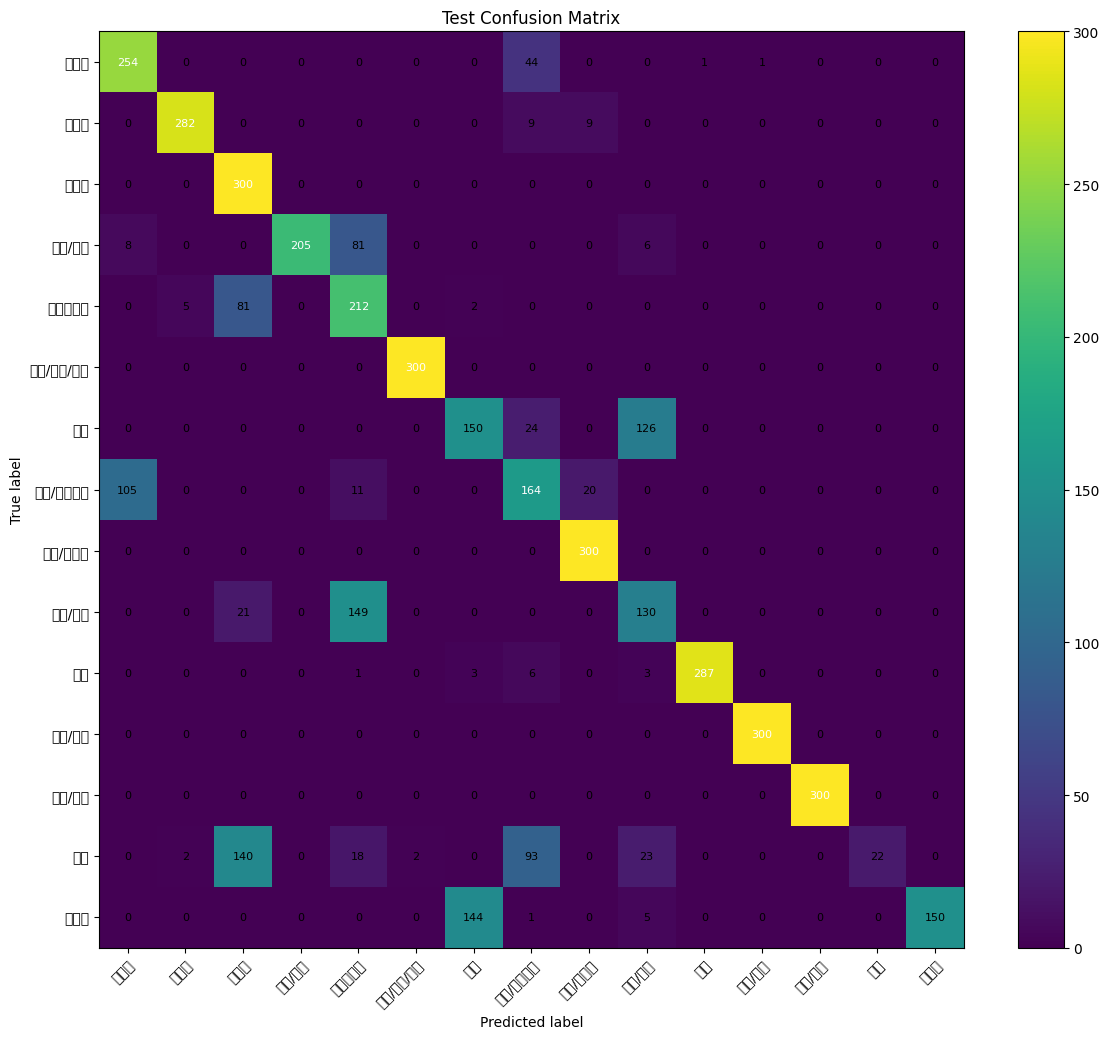

saved confusion matrix image: data/merchant_category_dataset_v1/training_outputs/test_confusion_matrix.png
saved confusion matrix csv  : data/merchant_category_dataset_v1/training_outputs/test_confusion_matrix.csv


In [43]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import platform


plt.rcParams['axes.unicode_minus'] = False
# 혼동행렬 시각화 및 저장
fig_w = max(12, num_labels * 0.8)
fig_h = max(10, num_labels * 0.7)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
im = ax.imshow(cm, interpolation='nearest', aspect='auto')
ax.figure.colorbar(im, ax=ax)

ax.set(
    xticks=np.arange(num_labels),
    yticks=np.arange(num_labels),
    xticklabels=[id2label[i] for i in labels_sorted],
    yticklabels=[id2label[i] for i in labels_sorted],
    ylabel='True label',
    xlabel='Predicted label',
    title='Test Confusion Matrix',
)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

thresh = cm.max() / 2.0 if cm.max() > 0 else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, format(cm[i, j], 'd'),
            ha='center', va='center',
            color='white' if cm[i, j] > thresh else 'black',
            fontsize=8,
        )

fig.tight_layout()
cm_png_path = OUTPUT_ROOT / 'test_confusion_matrix.png'
plt.savefig(cm_png_path, dpi=180, bbox_inches='tight')
plt.show()
print('saved confusion matrix image:', cm_png_path)
print('saved confusion matrix csv  :', cm_path)


In [44]:
# ?? ?? ??
summary = {
    'model_name': MODEL_NAME,
    'selected_model_name': SELECTED_MODEL_NAME,
    'model_candidates': MODEL_CANDIDATES,
    'max_length': MAX_LENGTH,
    'num_epochs': NUM_EPOCHS,
    'learning_rate': LEARNING_RATE,
    'train_batch_size': TRAIN_BATCH_SIZE,
    'eval_batch_size': EVAL_BATCH_SIZE,
    'gradient_accumulation_steps': GRADIENT_ACCUMULATION_STEPS,
    'weight_decay': WEIGHT_DECAY,
    'warmup_step_ratio': WARMUP_STEP_RATIO,
    'max_grad_norm': MAX_GRAD_NORM,
    'num_folds': NUM_FOLDS,
    'baseline_valid_metrics': baseline_valid_metrics,
    'baseline_test_metrics': baseline_test_metrics,
    'test_metrics': test_metrics,
    'service_test_metrics': service_test_metrics,
    'final_valid_metrics': final_valid_metrics,
    'service_valid_metrics': service_valid_metrics,
    'service_fallback_label': SERVICE_FALLBACK_LABEL,
    'selected_service_threshold': selected_service_threshold,
    'baseline_vs_finetuned_metrics_path': str(baseline_vs_finetuned_path),
}
summary_path = OUTPUT_ROOT / 'run_summary.json'
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print('saved summary:', summary_path)


saved summary: data/merchant_category_dataset_v1/training_outputs/run_summary.json



## 4) Inference Example

저장된 모델을 불러와 단건 추론하는 예시입니다.


In [49]:
from transformers import pipeline
import re
import unicodedata

def normalize_service_merchant_text(merchant_text: str) -> str:
    text = unicodedata.normalize('NFKC', str(merchant_text or ''))
    text = text.replace('\r', ' ').replace('\n', ' ')
    text = re.sub(r'\s+', ' ', text).strip()
    return text.casefold()

def build_service_input_record(merchant_text: str) -> dict[str, str]:
    raw_text = unicodedata.normalize('NFKC', str(merchant_text or ''))
    raw_text = raw_text.replace('\r', ' ').replace('\n', ' ')
    raw_text = re.sub(r'\s+', ' ', raw_text).strip()
    normalized_merchant_text = normalize_service_merchant_text(raw_text)
    return {
        'merchant_text': raw_text,
        'normalized_merchant_text': normalized_merchant_text,
        'input_text': f'{raw_text} [SEP] {normalized_merchant_text}',
    }

def normalize_pipeline_top_k_predictions(top_k_predictions):
    if isinstance(top_k_predictions, dict):
        return [top_k_predictions]
    if isinstance(top_k_predictions, list) and top_k_predictions and isinstance(top_k_predictions[0], list):
        return top_k_predictions[0]
    return top_k_predictions

def predict_service_output(merchant_text: str, threshold: float = selected_service_threshold):
    input_record = build_service_input_record(merchant_text)
    top_k_predictions = normalize_pipeline_top_k_predictions(clf(input_record['input_text']))
    if not top_k_predictions:
        raise ValueError('text-classification pipeline returned no predictions')
    top_prediction = top_k_predictions[0]
    raw_label = top_prediction['label']
    confidence = float(top_prediction['score'])
    service_label = SERVICE_FALLBACK_LABEL if confidence < threshold else raw_label
    return {
        **input_record,
        'raw_label': raw_label,
        'confidence': confidence,
        'service_label': service_label,
        'fallback_applied': service_label != raw_label,
        'top_k_predictions': top_k_predictions,
    }

clf = pipeline(
    'text-classification',
    model=str(best_model_dir),
    tokenizer=str(best_model_dir),
    device=0 if torch.cuda.is_available() else -1,
    top_k=3,
)

examples = [
    '스타벅스코리아 강남R점',
    '넷플릭스서비시스코리아',
    'GS25 대구수성점',
    '하나카드결제',
    '스터디카페 구',
    'KIS정보통신',
    '무신사 스토어'
]

for text in examples:
    print('RAW INPUT:', text)
    print(predict_service_output(text))


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RAW INPUT: 스타벅스코리아 강남R점
{'merchant_text': '스타벅스코리아 강남R점', 'normalized_merchant_text': '스타벅스코리아 강남r점', 'input_text': '스타벅스코리아 강남R점 [SEP] 스타벅스코리아 강남r점', 'raw_label': '카페', 'confidence': 0.993809163570404, 'service_label': '카페', 'fallback_applied': False, 'top_k_predictions': [{'label': '카페', 'score': 0.993809163570404}, {'label': '구독료', 'score': 0.0005682916380465031}, {'label': '생활/반려동물', 'score': 0.000546793919056654}]}
RAW INPUT: 넷플릭스서비시스코리아
{'merchant_text': '넷플릭스서비시스코리아', 'normalized_merchant_text': '넷플릭스서비시스코리아', 'input_text': '넷플릭스서비시스코리아 [SEP] 넷플릭스서비시스코리아', 'raw_label': '구독료', 'confidence': 0.9930451512336731, 'service_label': '구독료', 'fallback_applied': False, 'top_k_predictions': [{'label': '구독료', 'score': 0.9930451512336731}, {'label': '기타서비스', 'score': 0.0008711562259122729}, {'label': '식비', 'score': 0.0007001564954407513}]}
RAW INPUT: GS25 대구수성점
{'merchant_text': 'GS25 대구수성점', 'normalized_merchant_text': 'gs25 대구수성점', 'input_text': 'GS25 대구수성점 [SEP] gs25 대구수성점', 'raw_label': 

In [50]:
%pip install -U huggingface_hub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [51]:
# 5) Hugging Face Deployment
from getpass import getpass
from tempfile import TemporaryDirectory
import os
from dotenv import load_dotenv
from huggingface_hub import HfApi

load_dotenv()


HF_REPO_ID = 'kakao1513/merchant-consumption-category-discriminator-v1'
HF_TOKEN = os.getenv('HF_TOKEN')  # Fill manually before running, or leave as None to be prompted securely.
HF_PRIVATE = False
HF_ARTIFACT_RELATIVE_PATHS = [
    'run_summary.json',
    'baseline_vs_finetuned_metrics.csv',
    'test_classification_report.csv',
    'test_service_classification_report.csv',
    'test_predictions.csv',
    'valid_service_threshold_sweep.csv',
    'test_confusion_matrix.csv',
    'test_confusion_matrix.png',
    'kfold/cv_metrics.csv',
]


def load_hf_run_summary(summary_path: Path) -> dict:
    summary_path = Path(summary_path)
    if not summary_path.exists():
        raise FileNotFoundError(
            f'run_summary.json not found: {summary_path}. Run the training/evaluation cells first.'
        )
    return json.loads(summary_path.read_text(encoding='utf-8'))


def format_hf_metric(value) -> str:
    if value is None:
        return 'N/A'
    try:
        return f'{float(value):.4f}'
    except (TypeError, ValueError):
        return str(value)


def build_hf_model_card(summary: dict, repo_id: str, repo_url: str) -> str:
    selected_model_name = summary.get('selected_model_name') or summary.get('model_name', 'unknown')
    final_valid_metrics = summary.get('final_valid_metrics', {})
    test_metrics = summary.get('test_metrics', {})
    service_test_metrics = summary.get('service_test_metrics', {})
    selected_service_threshold = summary.get('selected_service_threshold')
    return f'''---
language:
- ko
tags:
- text-classification
- korean
- transformers
- merchant-category
library_name: transformers
pipeline_tag: text-classification
---

# Merchant Consumption Category Discriminator v1

- Repository: {repo_url}
- Base checkpoint: `{selected_model_name}`
- Input format: `merchant_text [SEP] normalized_merchant_text`
- Validation macro F1: `{format_hf_metric(final_valid_metrics.get('f1_macro'))}`
- Test macro F1: `{format_hf_metric(test_metrics.get('f1_macro'))}`
- Service fallback test macro F1: `{format_hf_metric(service_test_metrics.get('f1_macro'))}`
- Selected service fallback threshold: `{format_hf_metric(selected_service_threshold)}`

## Summary

This model classifies Korean merchant strings into consumption categories for the `more` service.
The labels are weakly supervised merchant-category labels derived from internal merchant-category pipelines, so boundary errors can still appear around visually similar service names.

## Files

- Model weights and tokenizer are uploaded at the repository root.
- Training logs and evaluation artifacts are uploaded under `artifacts/`.

## Inference

```python
from transformers import pipeline

clf = pipeline(
    'text-classification',
    model='{repo_id}',
    tokenizer='{repo_id}',
    top_k=3,
)

clf('스타벅스 강남R점 [SEP] 스타벅스 강남R점')
```

## Limitations

- This classifier is optimized for merchant text classification, not full transaction understanding.
- Low-confidence predictions may still need the downstream service fallback rule.
'''


def collect_hf_artifact_paths(output_root: Path) -> tuple[list[Path], list[Path]]:
    output_root = Path(output_root)
    existing_paths = []
    missing_paths = []
    for relative_path in HF_ARTIFACT_RELATIVE_PATHS:
        artifact_path = output_root / relative_path
        if artifact_path.exists():
            existing_paths.append(artifact_path)
        else:
            missing_paths.append(artifact_path)
    return existing_paths, missing_paths


hf_output_root = Path(OUTPUT_ROOT)
hf_model_dir = Path(best_model_dir) if 'best_model_dir' in globals() else hf_output_root / 'saved_model'
hf_summary_path = Path(summary_path) if 'summary_path' in globals() else hf_output_root / 'run_summary.json'

if not hf_model_dir.exists():
    raise FileNotFoundError(
        f'saved_model directory not found: {hf_model_dir}. Run the training/evaluation cells first.'
    )

hf_token = (HF_TOKEN or '').strip()
if not hf_token:
    hf_token = getpass('Enter Hugging Face token for model upload: ').strip()
if not hf_token:
    raise ValueError('A Hugging Face token is required to upload the model repository.')

summary = load_hf_run_summary(hf_summary_path)
artifact_paths, missing_artifact_paths = collect_hf_artifact_paths(hf_output_root)
artifact_allow_patterns = [
    str(path.relative_to(hf_output_root)).replace('\\', '/')
    for path in artifact_paths
]

api = HfApi(token=hf_token)
repo_info = api.create_repo(
    repo_id=HF_REPO_ID,
    repo_type='model',
    private=HF_PRIVATE,
    exist_ok=True,
)
repo_url = getattr(repo_info, 'repo_url', None) or f'https://huggingface.co/{HF_REPO_ID}'

api.upload_folder(
    repo_id=HF_REPO_ID,
    repo_type='model',
    folder_path=str(hf_model_dir),
    path_in_repo='',
    token=hf_token,
    commit_message='Upload trained merchant category model',
)

if artifact_allow_patterns:
    api.upload_folder(
        repo_id=HF_REPO_ID,
        repo_type='model',
        folder_path=str(hf_output_root),
        path_in_repo='artifacts',
        allow_patterns=artifact_allow_patterns,
        token=hf_token,
        commit_message='Upload training logs and evaluation artifacts',
    )

with TemporaryDirectory() as tmp_dir:
    readme_path = Path(tmp_dir) / 'README.md'
    readme_path.write_text(
        build_hf_model_card(summary=summary, repo_id=HF_REPO_ID, repo_url=repo_url),
        encoding='utf-8',
    )
    api.upload_file(
        path_or_fileobj=str(readme_path),
        path_in_repo='README.md',
        repo_id=HF_REPO_ID,
        repo_type='model',
        token=hf_token,
        commit_message='Update README with latest training summary',
    )

print('Hugging Face repository:', repo_url)
print('Uploaded model directory:', hf_model_dir)
print('Uploaded artifacts:')
for artifact_path in artifact_paths:
    print('-', artifact_path.relative_to(hf_output_root).as_posix())

if missing_artifact_paths:
    print('Skipped missing artifacts:')
    for artifact_path in missing_artifact_paths:
        print('-', artifact_path.relative_to(hf_output_root).as_posix())


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Hugging Face repository: https://huggingface.co/kakao1513/merchant-consumption-category-discriminator-v1
Uploaded model directory: data/merchant_category_dataset_v1/training_outputs/saved_model
Uploaded artifacts:
- run_summary.json
- baseline_vs_finetuned_metrics.csv
- test_classification_report.csv
- test_service_classification_report.csv
- test_predictions.csv
- valid_service_threshold_sweep.csv
- test_confusion_matrix.csv
- test_confusion_matrix.png
- kfold/cv_metrics.csv
